### 1.FETCHING SENTINEL-2 DATA

In [ ]:
import pystac_client
import planetary_computer

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

time_range = "2023-10-01/2023-10-31"
bbox = [6.40, 9.40, 6.70, 9.80]

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime=time_range,
    query={"eo:cloud_cover": {"lt":40}},
)
items = list(search.items())
print(f"Found {len(items)} scenes")

if not items:
    raise RuntimeError("No Sentinel-2 scenes found for the given bbox and date range.")

item = items[0]
print(f"Selected scene : {item.id}")
print(f"Cloud cover    : {item.properties['eo:cloud_cover']:.1f}%")
print(f"Sensing date   : {item.properties['datetime']}")


#### Cloud cover summary for the selected scene
Within the specified bounding box and October 2023 time window, no Sentinel-2 L2A scene met the <20% cloud cover threshold. The least cloudy available scene had a cloud cover of 34.8%, and was therefore selected as the best available observation for analysis.

Given the absence of clearer observations within the query constraints, this scene represents the best trade-off between temporal relevance and atmospheric conditions.

### 2. LOADING SPECTRAL BANDS

In [48]:
import rioxarray 

b8a = rioxarray.open_rasterio(item.assets["B8A"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
b11 = rioxarray.open_rasterio(item.assets["B11"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
b12 = rioxarray.open_rasterio(item.assets["B12"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()

b02 = rioxarray.open_rasterio(item.assets["B02"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
b02_20m = b02.rio.reproject_match(b8a)

b04 = rioxarray.open_rasterio(item.assets["B04"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
b04_20m = b04.rio.reproject_match(b8a)


### 3.CLOUD MASKING

In [49]:
import rioxarray
import numpy as np

# 3.1 Building the mask from SCL
scl = rioxarray.open_rasterio(item.assets["SCL"].href).rio.clip_box(*bbox, crs="EPSG:4326").squeeze()
invalid_classes = [0, 1, 3, 8, 9, 10]
mask = np.isin(scl.values, invalid_classes)

# 3.2 Converting to float32
b02_float = b02_20m.values.astype(np.float32)
b04_float = b04_20m.values.astype(np.float32)
b8a_float = b8a.values.astype(np.float32)
b11_float = b11.values.astype(np.float32)
b12_float = b12.values.astype(np.float32)

# 3.3 Applying mask and setting the invalid pixels to NaN
b02_float[mask] = np.nan
b04_float[mask] = np.nan
b8a_float[mask] = np.nan
b11_float[mask] = np.nan
b12_float[mask] = np.nan

# 3.4 Valid pixels
b02_masked = b02_float
b04_masked = b04_float
b8a_masked = b8a_float
b11_masked = b11_float
b12_masked = b12_float


### 4.REFLECTANCE CONVERSION AND INDEX COMPUTATION

In [50]:
import numpy as np

## 4.1 Divide DN values by 10000 to normalize reflectance
b02_ref = b02_masked / 10000
b04_ref = b04_masked / 10000
b8a_ref = b8a_masked / 10000
b11_ref = b11_masked / 10000
b12_ref = b12_masked / 10000

## 4.2 surface reflectance
albedo = (0.356*b02_ref + 0.130*b04_ref + 0.373*b8a_ref 
          + 0.085*b11_ref + 0.072*b12_ref - 0.0018)
albedo = np.clip(albedo, 0, 1)

## 4.3 Index computation
ndvi = (b8a_ref - b04_ref) / (b8a_ref + b04_ref)

## 4.4 Computing mean and standard deviation for the indices
albedo_mean = float(np.nanmean(albedo))
albedo_std = float(np.nanstd(albedo))
ndvi_mean   = float(np.nanmean(ndvi))
ndvi_std =  float(np.nanstd(ndvi))

print(f"Albedo-mean: {albedo_mean:.4f}")
print(f"Albedo-std: {albedo_std:.4f}")
print(f"NDVI-mean:   {ndvi_mean:.4f}")
print(f"NDVI-std:   {ndvi_std:.4f}")


Albedo-mean: 0.3281
Albedo-std: 0.0362
NDVI-mean:   0.4096
NDVI-std:   0.1113


##### 4B. INDICES INTERPRETATION
- The NDVI mean suggests grassland and shrubs, and due to the lower NDVI standard deviation, this suggests a uniform vegetation cover(grassland and shrubs).
- High NDVI mean compared to Albedo mean confirm a photosynthetically active vegetation.
- low Albedo standard deviation compared to NDVI standard deviation confirms a low surface reflectance. 

### 5.VISUALIZATION

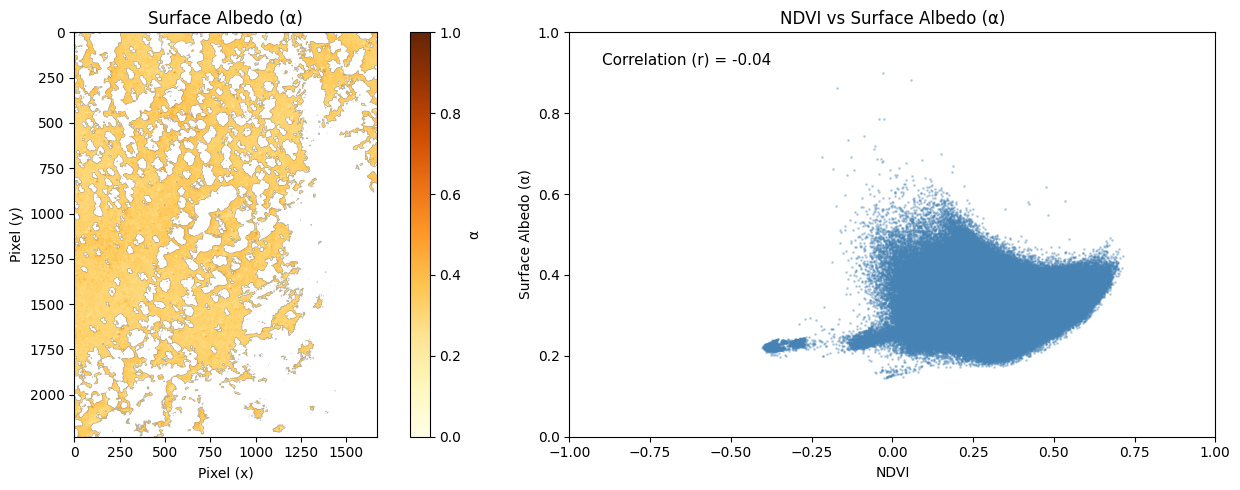

In [52]:
import matplotlib.pyplot as plt
import numpy as np

## 5.1 Creating a valid data mask
valid = ~np.isnan(albedo) & ~np.isnan(ndvi)
albedo_valid = albedo[valid]
ndvi_valid   = ndvi[valid]

corr = np.corrcoef(ndvi_valid, albedo_valid)[0, 1]

## 5.2 Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left Spatial map of albedo
im = ax1.imshow(albedo, cmap="YlOrBr", vmin=0, vmax=1)
ax1.set_title("Surface Albedo (α)")
ax1.set_xlabel("Pixel (x)")
ax1.set_ylabel("Pixel (y)")
plt.colorbar(im, ax=ax1, label="α")

# Right Scatter plot NDVI vs Albedo
ax2.scatter(ndvi_valid, albedo_valid, s=1, alpha=0.3, color="steelblue")
ax2.set_title("NDVI vs Surface Albedo (α)")
ax2.set_xlabel("NDVI")
ax2.set_ylabel("Surface Albedo (α)")
ax2.set_xlim(-1, 1)
ax2.set_ylim(0, 1)
ax2.text(0.05, 0.95, f"Correlation (r) = {corr:.2f}",
         transform=ax2.transAxes,
         fontsize=11,
         verticalalignment='top')

plt.tight_layout()
plt.savefig("../outputs/albedo_ndvi_plot.png", dpi=150, bbox_inches="tight")
plt.show()


### 6. INTERPRETATION
- There is a negative correlation in the scatter that confirms **High NDVI / Low Albedo** meaning a dense canopy absorbing incoming radiation; photosynthetically active vegetation.
- Even with moderate cloud contamination, the expected inverse relationship between NDVI and albedo is still observable, where higher vegetation density generally corresponds to lower surface reflectance.
